# Twitter sentiment: how good is a simple model, honestly?

**Question:** can a TF-IDF + logistic regression model tell positive from negative tweets about brands and games, and how accurate is it *on tweets it has never seen*?

**Data:** [Twitter Entity Sentiment Analysis](https://www.kaggle.com/datasets/jp797498e/twitter-entity-sentiment-analysis) (Kaggle), 74,682 rows. Only Positive and Negative tweets are used.

**Main finding:** the dataset contains each tweet about **six times in slightly reworded versions**. A random train/test split puts near-copies of the same tweet on both sides and reports **86.7 %** accuracy. Splitting by tweet ID, so the model is tested on genuinely new tweets, gives **80.5 %**. The second number is the one that would hold in production.

In [1]:
%config InlineBackend.figure_formats = ["svg"]
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline

matplotlib.rcParams["svg.fonttype"] = "none"
SEED = 42
CHARTS = Path("images"); CHARTS.mkdir(exist_ok=True)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"

def style(ax, title, subtitle=None):
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK, pad=22 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=10, color=MUTED)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)

## 1. Load and check the data

In [2]:
cols = ["tweet_id", "entity", "sentiment", "text"]
train = pd.read_csv("data/raw/twitter_training.csv", header=None, names=cols)
valid = pd.read_csv("data/raw/twitter_validation.csv", header=None, names=cols)

print("rows:", len(train), "| unique tweet IDs:", train["tweet_id"].nunique(),
      "| rows per ID:", round(len(train) / train["tweet_id"].nunique(), 1))
print("missing text:", train["text"].isna().sum(), "| exact duplicate texts:", train["text"].duplicated().sum())
train["sentiment"].value_counts()

rows: 74682 | unique tweet IDs: 12447 | rows per ID: 6.0
missing text: 686 | exact duplicate texts: 5190


sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64

Six rows per tweet ID. Looking at one ID shows why: the same tweet appears in several paraphrased versions.

In [3]:
pd.set_option("display.max_colwidth", 90)
train.loc[train["tweet_id"] == 2401, ["tweet_id", "sentiment", "text"]]

,tweet_id,sentiment,text
0,2401,Positive,"im getting on borderlands and i will murder you all ,"
1,2401,Positive,"I am coming to the borders and I will kill you all,"
2,2401,Positive,"im getting on borderlands and i will kill you all,"
3,2401,Positive,"im coming on borderlands and i will murder you all,"
4,2401,Positive,"im getting on borderlands 2 and i will murder you me all,"
5,2401,Positive,"im getting into borderlands and i can murder you all,"


In [4]:
data = train[train["sentiment"].isin(["Positive", "Negative"])].dropna(subset=["text"]).copy()
data["text"] = data["text"].astype(str)
data["label"] = (data["sentiment"] == "Positive").astype(int)
print(len(data), "positive/negative tweets |", round(data["label"].mean() * 100, 1), "% positive")

43013 positive/negative tweets | 48.0 % positive


Rows with missing text are **dropped**, not filled with an empty string: an empty text carries no sentiment, so keeping it would only teach the model noise.

## 2. Two ways to split, two very different answers

In [5]:
def make_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", max_features=5000)),
        ("clf", LogisticRegression(max_iter=1000)),
    ])

def evaluate(train_part, test_part):
    m = make_model().fit(train_part["text"], train_part["label"])
    pred = m.predict(test_part["text"])
    return m, accuracy_score(test_part["label"], pred), f1_score(test_part["label"], pred, average="macro")

# (a) random split: the original approach
tr_a, te_a = train_test_split(data, test_size=0.2, random_state=SEED, stratify=data["label"])
_, acc_random, f1_random = evaluate(tr_a, te_a)

# (b) grouped split: all versions of a tweet stay on the same side
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
i_tr, i_te = next(gss.split(data, groups=data["tweet_id"]))
tr_b, te_b = data.iloc[i_tr], data.iloc[i_te]
model, acc_grouped, f1_grouped = evaluate(tr_b, te_b)

# the dataset's own validation file
val = valid[valid["sentiment"].isin(["Positive", "Negative"])].copy()
val["label"] = (val["sentiment"] == "Positive").astype(int)
_, acc_val, f1_val = evaluate(data, val)
print(f"Validation file: {val['tweet_id'].isin(train['tweet_id']).mean():.0%} of its tweet IDs also appear in training,",
      f"{val['text'].isin(train['text']).mean():.0%} with identical text")

baseline = accuracy_score(te_b["label"], DummyClassifier(strategy="most_frequent").fit(tr_b["text"], tr_b["label"]).predict(te_b["text"]))

comparison = pd.DataFrame([
    {"evaluation": "Random split (leaky)", "accuracy": acc_random, "macro_f1": f1_random},
    {"evaluation": "Validation file (leaky)", "accuracy": acc_val, "macro_f1": f1_val},
    {"evaluation": "Grouped by tweet ID (honest)", "accuracy": acc_grouped, "macro_f1": f1_grouped},
    {"evaluation": "Always predict majority class", "accuracy": baseline, "macro_f1": np.nan},
]).round(3)
comparison.to_csv(RESULTS / "evaluation_comparison.csv", index=False)
comparison

Validation file: 100% of its tweet IDs also appear in training, 59% with identical text


,evaluation,accuracy,macro_f1
0,Random split (leaky),0.867,0.866
1,Validation file (leaky),0.932,0.932
2,Grouped by tweet ID (honest),0.805,0.804
3,Always predict majority class,0.511,NaN


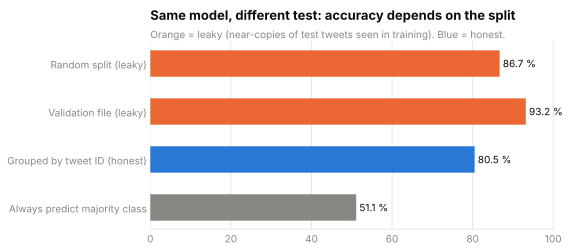

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
c = comparison.iloc[::-1]
colors = [MUTED, BLUE, ORANGE, ORANGE]
ax.barh(c["evaluation"], c["accuracy"] * 100, color=colors, height=0.55)
for y, v in enumerate(c["accuracy"] * 100):
    ax.text(v + 0.8, y, f"{v:.1f} %", va="center", fontsize=10, color=INK)
ax.set_xlim(0, 100)
ax.tick_params(axis="y", colors=INK)
style(ax, "Same model, different test: accuracy depends on the split",
      "Orange = leaky (near-copies of test tweets seen in training). Blue = honest.")
fig.tight_layout(); fig.savefig(CHARTS / "leakage_effect.svg"); plt.show()

**The honest accuracy is 80 %, not 87 %.** The provided validation file is even more misleading, because every tweet in it also appears in the training file. For this dataset, only a split by tweet ID says how the model would do on new tweets.

## 3. What has the model learned?

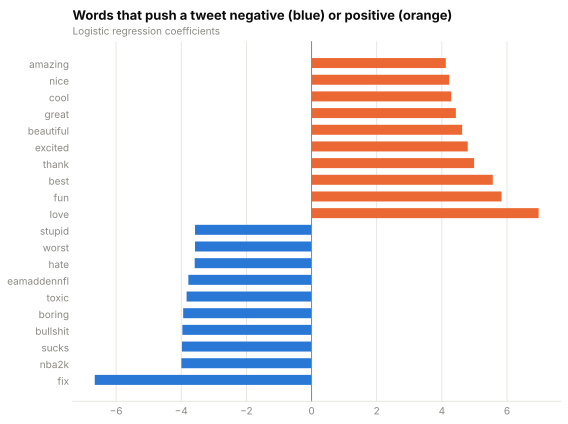

In [7]:
vec, clf = model.named_steps["tfidf"], model.named_steps["clf"]
coef = pd.Series(clf.coef_[0], index=vec.get_feature_names_out())
words = pd.concat([coef.nsmallest(10), coef.nlargest(10)])
words.rename("coefficient").round(3).to_csv(RESULTS / "top_words.csv")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(words.index, words.values, color=[BLUE if v < 0 else ORANGE for v in words.values], height=0.6)
ax.axvline(0, color=MUTED, linewidth=1)
ax.tick_params(axis="y", colors=INK)
style(ax, "Words that push a tweet negative (blue) or positive (orange)", "Logistic regression coefficients")
fig.tight_layout(); fig.savefig(CHARTS / "top_words.svg"); plt.show()

Most words make sense (*love*, *fun*, *best* vs. *sucks*, *boring*, *worst*). Two are a warning sign: **nba2k** and **eamaddennfl** are brand names, not opinions. The model has partly learned *which products people complain about* instead of *how* they talk, a shortcut that would fail on a new set of brands. Removing entity names from the text would make the model more general.

## 4. Where does it go wrong?

In [8]:
te = te_b.copy()
te["pred"] = model.predict(te["text"])
errors = te[te["pred"] != te["label"]]
print(f"{len(errors)} of {len(te)} test tweets misclassified")
errors.sample(8, random_state=SEED)[["entity", "sentiment", "text"]]

1680 of 8612 test tweets misclassified


,entity,sentiment,text
72296,TomClancysGhostRecon,Positive,.
24781,Google,Negative,I will never understand if I continue to trust that freedom deprives thieves of revenu...
11049,Xbox(Xseries),Positive,"The reflexes of this game are really amazing, sometimes players wonder if it's just tr..."
2587,CallOfDutyBlackopsColdWar,Positive,"""This will be my year"""
43584,PlayerUnknownsBattlegrounds(PUBG),Negative,. . Me pretending to be alright : pic.twitter.com/alDZJWadES
24647,Google,Positive,"21| My post ""Date Ideas in Gloucestershire"" from best website best found in Google!! :..."
74141,Nvidia,Negative,"@nvidia Hey, I have GTX 4 and this am experiencing low fps while gaming and streaming ..."
55954,TomClancysRainbowSix,Positive,. html BestSeason. com @Rainbow6Game.


Typical errors are sarcasm, negation spread over several words ("not bad at all"), and tweets whose sentiment depends on context the model never sees (game or brand news). A bag-of-words model cannot read word order, so these are expected limits rather than bugs.

## Conclusions

- A simple TF-IDF + logistic regression model reaches **80.5 % accuracy on genuinely new tweets** (always guessing the majority class: 51 %).
- The commonly reported ~87 % comes from **leakage**: paraphrased copies of test tweets in the training data.
- Next steps: character n-grams or a small pre-trained transformer to handle negation and sarcasm, always evaluated with the grouped split.

## Limitations

- Labels come from the dataset and are noisy (some "Positive" tweets read neutral).
- Tweets are about a fixed set of entities (mostly games and tech brands), so results may not transfer to other domains.